# Flight-fare prediction with Linear Regression

Predict `Price` in rupees from the itinerary known at prediction time. Start with a median-fare baseline, evaluate ordinary least squares on labeled holdouts, then refit on all labeled rows and export predictions for the unlabeled workbook.

Run all cells from this folder using the Preparation project's Python environment. The notebook reads the Excel inputs directly and reuses `audit.py` for standard cleaning. Code comments explain each step. In a new project, keep the baseline, evaluation, and inference flow, then replace the target, feature definitions, and split strategy.

In [1]:
from pathlib import Path  # Build paths relative to the project folder.
import matplotlib.pyplot as plt  # Draw the evaluation plots.
import numpy as np  # Encode cyclic features and validate numeric outputs.
import pandas as pd  # Work with the cleaned tables.
from IPython.display import display  # Render tables inside the notebook.
from sklearn.base import clone  # Start every fit with fresh model parameters.
from sklearn.compose import ColumnTransformer  # Apply separate numeric and categorical preprocessing.
from sklearn.dummy import DummyRegressor  # Benchmark a constant median-fare prediction.
from sklearn.impute import SimpleImputer  # Learn missing-value replacements from training rows.
from sklearn.linear_model import LinearRegression  # Fit ordinary least squares.
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score  # Score labeled predictions.
from sklearn.model_selection import GroupShuffleSplit  # Hold out entire itinerary groups.
from sklearn.pipeline import Pipeline  # Bundle preprocessing and the estimator.
from sklearn.preprocessing import OneHotEncoder  # Encode categories for a linear model.
from audit import clean, extract_file, fix_data_types  # Reuse this project's Excel cleaning functions.

ROOT = Path.cwd()  # The notebook kernel runs in this project folder.
TRAIN_FILE = ROOT / "data" / "raw" / "Data_Train.xlsx"  # Contains the fare labels.
TEST_FILE = ROOT / "data" / "raw" / "Test_set.xlsx"  # Contains itineraries to predict.
PREDICTIONS_FILE = ROOT / "flight_fare_predictions.csv"  # Store predictions in original workbook order.
TARGET = "Price"  # Keep the label out of the feature matrix.

## 1. Load the labeled workbook and build features

Represent departure and arrival times on a circle so that 23:59 and 00:01 are close. Treat durations below 30 minutes as missing for this dataset. This is a deliberate heuristic that catches the five-minute Mumbai–Hyderabad entry and zeros produced by the upstream parser. Keep the original duration in the cleaned frame for diagnostics.

Use airline, endpoints, departure weekday, stop count, duration, and scheduled times. Reserve the full route for grouping during validation. Exclude `Additional_Info` because the workbook does not establish whether all its values would be available at the intended prediction time.

In [2]:
CATEGORICAL = ["Airline", "Source", "Destination", "Journey_weekday"]  # Treat each value as a category.
NUMERIC = ["Total_Stops", "Duration_minutes", "Departure_sin", "Departure_cos", "Arrival_sin", "Arrival_cos"]  # Use these as numerical inputs.
MIN_DURATION_MINUTES = 30  # Apply the same dataset-specific lower bound everywhere.

def make_features(frame):  # Transform any cleaned workbook without reading the target.
    features = frame[["Airline", "Source", "Destination", "Total_Stops", "Duration_minutes"]].copy()  # Select raw predictors.
    features["Journey_weekday"] = frame["Date_of_Journey"].dt.day_name()  # Capture weekly patterns.
    features["Duration_minutes"] = features["Duration_minutes"].where(features["Duration_minutes"] >= MIN_DURATION_MINUTES)  # Mask suspect durations.
    for prefix, output_name in [("Dep_Time", "Departure"), ("Arrival_Time", "Arrival")]:  # Encode both scheduled clock times.
        minutes = frame[f"{prefix}_hour"] * 60 + frame[f"{prefix}_minute"]  # Convert the clock time to minutes since midnight.
        angle = 2 * np.pi * minutes / (24 * 60)  # Map a day onto one full revolution.
        features[f"{output_name}_sin"] = np.sin(angle)  # Store the vertical component of the clock position.
        features[f"{output_name}_cos"] = np.cos(angle)  # Store the horizontal component of the clock position.
    return features[CATEGORICAL + NUMERIC]  # Keep a consistent input schema for training and inference.

raw_train = extract_file(TRAIN_FILE, training=True)  # Validate the Excel headers and read labeled rows.
labeled = clean(fix_data_types(raw_train), training=True).reset_index(drop=True)  # Apply the existing training-only row filters.
assert labeled["Date_of_Journey"].notna().all(), "Journey dates are required for chronological validation."  # Guard the date split.
assert labeled[TARGET].gt(0).all() and np.isfinite(labeled[TARGET]).all(), "Training fares must be positive and finite."  # Guard regression targets.
X = make_features(labeled)  # Generate predictors without the target.
y = labeled[TARGET]  # Keep the actual fare separately.
display(pd.Series({"raw rows": len(raw_train), "labeled rows after cleaning": len(labeled), "suspect durations masked": X["Duration_minutes"].isna().sum()}))  # Verify data preparation counts.
display(X.head(3))  # Inspect the model's feature schema before fitting.

drop_missing: 10683 -> 10682 rows
deduplicate: 10682 -> 10460 rows


raw rows                       10683
labeled rows after cleaning    10460
suspect durations masked           1
dtype: int64

,Airline,Source,Destination,Journey_weekday,Total_Stops,Duration_minutes,Departure_sin,Departure_cos,Arrival_sin,Arrival_cos
0,IndiGo,Banglore,Delhi,Sunday,0.0,170.0,-0.422618,0.906308,0.300706,0.953717
1,Air India,Kolkata,Banglore,Wednesday,2.0,445.0,0.999048,0.043619,-0.321439,-0.946930
2,Jet Airways,Delhi,Cochin,Sunday,2.0,1140.0,0.625923,-0.779884,0.915311,0.402747


## 2. Set up the baseline and linear model

The median baseline answers what the absolute error would look like if every itinerary received one fixed fare. The linear model uses median imputation for numbers and one-hot encoding for categories. The pipeline fits all learned preprocessing exclusively on the rows passed to `fit`.

Both holdouts and the export apply the same zero floor to model predictions, since fares cannot be negative. Diagnostics count how often the underlying linear model crosses that floor.

In [3]:
numeric_preprocessing = SimpleImputer(strategy="median", add_indicator=True)  # Fill missing numbers and mark columns with missing values during fitting.
categorical_preprocessing = Pipeline([  # Learn the categorical transformations in sequence.
    ("fill", SimpleImputer(strategy="constant", fill_value="Unknown")),  # Give missing category values a common token.
    ("encode", OneHotEncoder(handle_unknown="ignore")),  # Encode categories learned during training and allow unseen values.
])  # End the categorical preprocessing pipeline.
preprocessing = ColumnTransformer([  # Route each feature to the correct transformer.
    ("numeric", numeric_preprocessing, NUMERIC),  # Treat the numeric feature list as continuous measurements.
    ("categorical", categorical_preprocessing, CATEGORICAL),  # Learn category indicators from the fit data.
])  # End column selection.
linear_template = Pipeline([  # Put preprocessing and regression in a single fit/predict interface.
    ("preprocess", preprocessing),  # Apply the fitted feature transformations.
    ("regressor", LinearRegression()),  # Substitute this estimator to compare another regression model.
])  # End the model pipeline.
models = {"Median baseline": DummyRegressor(strategy="median"), "Linear regression": linear_template}  # Compare two estimators on each split.

def score(actual, predicted):  # Calculate the same metrics for each model and validation split.
    return {  # Keep the metric names and units visible in the results.
        "MAE (INR)": mean_absolute_error(actual, predicted),  # Mean absolute error in rupees.
        "RMSE (INR)": root_mean_squared_error(actual, predicted),  # Rupee error with extra weight on large misses.
        "R²": r2_score(actual, predicted),  # Compare squared error with the evaluation set's mean benchmark.
        "Bias (INR)": float(np.mean(predicted - np.asarray(actual))),  # Positive values mean overprediction on average.
    }  # Return one record for the metrics table.

## 3. Evaluate on labeled data

**Primary split.** Hold out the latest journey month to approximate prediction for later departures. The workbook has journey dates and lacks quote timestamps, so this does not measure true as-of forecasting at a given booking lead time.

**Secondary split.** Hold out about 20% of itinerary groups. Each group is defined by airline, journey date, endpoints, route, and departure clock time. This keeps repeated quotes for the same recorded itinerary together. The date ranges overlap by design.

Read MAE as the typical error scale averaged across fares, RMSE as a measure more sensitive to large errors, and bias as the direction of the average error. R² has its own mean-fare benchmark. Use the reported baseline MAE directly to compare against the median baseline.

In [4]:
journey_month = labeled["Date_of_Journey"].dt.to_period("M")  # Identify the month of each scheduled departure.
latest_month = journey_month.max()  # Reserve the most recent month as the primary holdout.
time_train = np.flatnonzero(journey_month < latest_month)  # Train on earlier journeys.
time_valid = np.flatnonzero(journey_month == latest_month)  # Evaluate on the full latest month.
assert len(time_train) and len(time_valid), "Chronological evaluation requires at least two months."  # Reject an unusable split.
assert labeled.iloc[time_train]["Date_of_Journey"].max() < labeled.iloc[time_valid]["Date_of_Journey"].min()  # Verify chronological separation.

itinerary_keys = ["Airline", "Date_of_Journey", "Source", "Destination", "Route", "Dep_Time_hour", "Dep_Time_minute"]  # Identify a recorded itinerary.
itinerary_groups = labeled.groupby(itinerary_keys, dropna=False).ngroup()  # Assign one group ID to each itinerary.
group_splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)  # Make one reproducible group holdout.
group_train, group_valid = next(group_splitter.split(X, y, groups=itinerary_groups))  # Generate positional row indices.
assert set(itinerary_groups.iloc[group_train]).isdisjoint(itinerary_groups.iloc[group_valid])  # Check that no itinerary group crosses the split.

splits = {"Latest month": (time_train, time_valid), "Grouped itineraries": (group_train, group_valid)}  # Reuse the split indices for both estimators.
scores = []  # Collect one metrics record per model and split.
holdout_predictions = {}  # Keep linear-model predictions for diagnostics.
for split_name, (fit_idx, valid_idx) in splits.items():  # Evaluate each validation strategy independently.
    for model_name, template in models.items():  # Fit both estimators on the same rows.
        fitted = clone(template).fit(X.iloc[fit_idx], y.iloc[fit_idx])  # Fit fresh preprocessing and model parameters on training rows.
        raw_predictions = fitted.predict(X.iloc[valid_idx])  # Generate predictions before enforcing the fare floor.
        predictions = np.maximum(raw_predictions, 0)  # Apply the same nonnegative rule used for the export.
        scores.append({  # Record the scores and counts for this run.
            "Split": split_name, "Model": model_name,  # Identify the run in the results table.
            "Train rows": len(fit_idx), "Validation rows": len(valid_idx),  # Show how much data each run used.
            **score(y.iloc[valid_idx], predictions), "Floored rows": int((raw_predictions < 0).sum()),  # Add the metrics and floor count.
        })  # Finish one metrics record.
        if model_name == "Linear regression":  # Keep the row-level values used in the diagnostic cells.
            holdout_predictions[split_name] = predictions  # Save scores in the same positional order as the validation rows.
results = pd.DataFrame(scores).set_index(["Split", "Model"])  # Organize the rows by protocol and model.
with pd.option_context("display.max_columns", None, "display.width", 140):  # Keep every metric visible in the output.
    display(results.round(3))  # Print evaluation results in the executed notebook.
print(f"Latest month held out: {latest_month}")  # Make the date cutoff explicit.
for split_name in splits:  # Quantify improvement against the median for each split.
    baseline = results.loc[(split_name, "Median baseline"), "MAE (INR)"]  # Get the baseline MAE from matching rows.
    model_mae = results.loc[(split_name, "Linear regression"), "MAE (INR)"]  # Get the corresponding model MAE.
    print(f"{split_name} MAE reduction: {100 * (baseline - model_mae) / baseline:.1f}%")  # Negative reduction would indicate a worse model.

Latest month held out: 2019-06
Latest month MAE reduction: 43.4%
Grouped itineraries MAE reduction: 42.2%


Train rows  Validation rows  MAE (INR)  RMSE (INR)     R²  Bias (INR)  Floored rows
Split               Model                                                                                                 
Latest month        Median baseline          7149             3311   3253.448    3814.113 -0.031    -661.153             0
                    Linear regression        7149             3311   1841.908    2273.874  0.634     566.810             0
Grouped itineraries Median baseline          8418             2042   3646.315    4855.479 -0.017    -633.540             0
                    Linear regression        8418             2042   2108.755    3274.548  0.537      -8.538             0

## 4. Diagnose errors on the latest-month holdout

Break down errors by stop count and by fares above the 90th percentile of the earlier training months. Include the row count for context when interpreting a slice. Review whether errors grow with fare size and whether the model systematically misses expensive itineraries.

,Rows,MAE_INR,Bias_INR
Total_Stops,,,
0.0,1030,1289.36,340.40
1.0,1753,2029.85,411.67
2.0,513,2242.98,1448.13
3.0,15,4102.89,4102.89


,Rows,MAE_INR,Bias_INR
Above training 90th percentile,,,
False,3214,1795.89,675.01
True,97,3366.54,-3018.22


,Airline,Source,Destination,Date_of_Journey,Total_Stops,Duration_minutes,Price,Prediction,Error,Absolute error,Above training 90th percentile
1827,Jet Airways,Delhi,Cochin,2019-06-27,1.0,620.0,18371,10593.95,-7777.05,7777.05,True
1881,Jet Airways,Delhi,Cochin,2019-06-27,1.0,715.0,18371,10728.16,-7642.84,7642.84,True
6481,Jet Airways,Delhi,Cochin,2019-06-24,1.0,715.0,18581,11232.18,-7348.82,7348.82,True
5563,Jet Airways,Delhi,Cochin,2019-06-24,1.0,660.0,18581,11255.96,-7325.04,7325.04,True
6605,Jet Airways,Delhi,Cochin,2019-06-24,1.0,620.0,18371,11097.97,-7273.03,7273.03,True


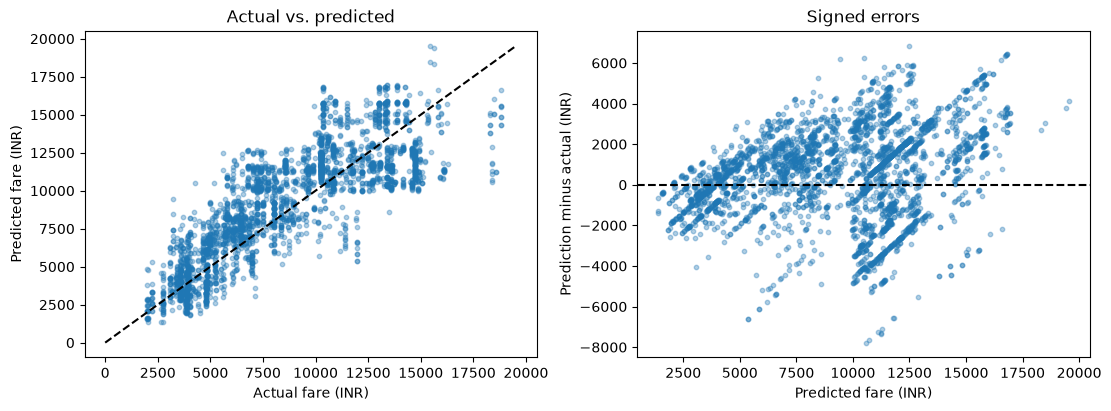

In [5]:
diagnostics = labeled.iloc[time_valid][["Total_Stops", "Duration_minutes", TARGET]].copy()  # Keep context and labels for the primary holdout.
diagnostics["Prediction"] = holdout_predictions["Latest month"]  # Align predictions by their existing row order.
diagnostics["Error"] = diagnostics["Prediction"] - diagnostics[TARGET]  # Record signed prediction error.
diagnostics["Absolute error"] = diagnostics["Error"].abs()  # Measure each miss in rupees.
high_fare_threshold = y.iloc[time_train].quantile(0.90)  # Set the expensive-fare cutoff using earlier training rows.
diagnostics["Above training 90th percentile"] = diagnostics[TARGET] > high_fare_threshold  # Label the expensive validation slice.
for group_by in ["Total_Stops", "Above training 90th percentile"]:  # Inspect both stop-count and price slices.
    display(diagnostics.groupby(group_by).agg(  # Summarize the validation errors in each slice.
        Rows=(TARGET, "size"),  # Report sample size.
        MAE_INR=("Absolute error", "mean"),  # Measure average absolute miss.
        Bias_INR=("Error", "mean"),  # Reveal systematic overprediction or underprediction.
    ).round(2))  # Show currency metrics to two decimal places.

worst = diagnostics.nlargest(5, "Absolute error")  # Surface the five biggest misses for inspection.
worst_context = labeled.loc[worst.index, ["Airline", "Source", "Destination", "Date_of_Journey"]]  # Keep the itinerary and date for each large miss.
display(worst_context.join(worst.round(2)))  # Round only the diagnostic numbers before joining the date.
figure, (actual_ax, error_ax) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")  # Place the diagnostic views side by side.
actual_ax.scatter(diagnostics[TARGET], diagnostics["Prediction"], s=10, alpha=0.35)  # Compare predicted fares with recorded fares.
upper = diagnostics[[TARGET, "Prediction"]].max().max()  # Cover the full fare range with the reference line.
actual_ax.plot([0, upper], [0, upper], linestyle="--", color="black")  # Mark perfect predictions.
actual_ax.set(xlabel="Actual fare (INR)", ylabel="Predicted fare (INR)", title="Actual vs. predicted")  # Label both axes in rupees.
error_ax.scatter(diagnostics["Prediction"], diagnostics["Error"], s=10, alpha=0.35)  # Look for residual patterns at different fitted fares.
error_ax.axhline(0, color="black", linestyle="--")  # Mark zero error.
error_ax.set(xlabel="Predicted fare (INR)", ylabel="Prediction minus actual (INR)", title="Signed errors")  # Make the residual direction explicit.
plt.show()  # Render the plots below this cell.

## 5. Refit and predict the unlabeled workbook

After measuring performance, fit a fresh pipeline on all labeled rows and apply it to `Test_set.xlsx`. The CSV uses Excel row numbers, starting with row 2 after the header. This preserves a link to the source even when two rows have the same itinerary.

The test workbook has no fare labels. Row counts, prediction ranges, unseen categories, and itinerary overlap are inference checks. The labeled holdouts above supply the accuracy metrics.

In [6]:
final_model = clone(linear_template).fit(X, y)  # Relearn preprocessing and coefficients from every labeled row.
raw_test = extract_file(TEST_FILE, training=False)  # Read the prediction workbook without expecting Price.
test = clean(fix_data_types(raw_test), training=False)  # Apply the same fixed transformations and preserve all input rows.
assert test.index.equals(raw_test.index) and len(test) == len(raw_test), "Inference must preserve workbook rows and order."  # Guard source alignment.
X_test = make_features(test)  # Generate the same feature columns used for fitting.
raw_test_predictions = final_model.predict(X_test)  # Predict all unlabeled fares with the refitted model.
assert np.isfinite(raw_test_predictions).all(), "All predicted fares must be finite."  # Reject unusable model outputs.
test_predictions = pd.DataFrame({  # Pair each prediction with its source row.
    "excel_row": test.index + 2,  # Offset by the header and one-based Excel row numbering.
    "predicted_price_inr": np.maximum(raw_test_predictions, 0).round(2),  # Apply the fare floor and round for display.
})  # Finish the export table.
test_predictions.to_csv(PREDICTIONS_FILE, index=False, float_format="%.2f")  # Export one row per input in workbook order.
seen_itineraries = pd.MultiIndex.from_frame(labeled[itinerary_keys])  # Collect the itinerary keys known during training.
test_itineraries = pd.MultiIndex.from_frame(test[itinerary_keys])  # Build comparable keys in the prediction workbook.
unseen_categories = {column: int((X_test[column].notna() & ~X_test[column].isin(X[column])).sum()) for column in CATEGORICAL}  # Count unfamiliar category values by feature.
display(pd.Series({  # Show the data and inference checks next to the export.
    "prediction rows": len(test_predictions),  # Verify that the export has one fare per row.
    "suspect durations masked": int(X_test["Duration_minutes"].isna().sum()),  # Report how often the duration heuristic applied.
    "test rows with itinerary also seen in training": int(test_itineraries.isin(seen_itineraries).sum()),  # Check how much itinerary overlap exists.
    "raw predictions below zero": int((raw_test_predictions < 0).sum()),  # Count predictions affected by the floor.
    **{f"unseen {column} rows": count for column, count in unseen_categories.items()},  # Show which category vocabularies missed a value.
}))  # Render inference checks.
display(test_predictions["predicted_price_inr"].describe().round(2))  # Check the range and spread of exported fares.
display(test_predictions.head())  # Inspect the first few outputs alongside their workbook row numbers.

largest_test = test_predictions.nlargest(5, "predicted_price_inr")  # Look for unusually high predictions that warrant manual review.
training_airline_counts = labeled["Airline"].value_counts()  # Measure how much labeled support each carrier has.
largest_context = test.loc[largest_test.index, ["Airline", "Source", "Destination", "Total_Stops"]]  # Recover context in the same order as the largest fares.
largest_context["Labeled airline rows"] = largest_context["Airline"].map(training_airline_counts).fillna(0).astype(int)  # Count labeled support for those carriers.
display(largest_test.join(largest_context))  # Show the most extreme predictions alongside their training support.

prediction rows                                   2671
suspect durations masked                             1
test rows with itinerary also seen in training    1613
raw predictions below zero                           0
unseen Airline rows                                  0
unseen Source rows                                   0
unseen Destination rows                              0
unseen Journey_weekday rows                          0
dtype: int64

count     2671.00
mean      9119.76
std       3604.81
min       1501.66
25%       6492.42
50%      10203.92
75%      11585.62
max      57911.30
Name: predicted_price_inr, dtype: float64

,excel_row,predicted_price_inr
0,2,10984.88
1,3,7856.13
2,4,11778.70
3,5,10779.52
4,6,3904.94


,excel_row,predicted_price_inr,Airline,Source,Destination,Total_Stops,Labeled airline rows
1802,1804,57911.30,Jet Airways Business,Banglore,Delhi,1,6
1819,1821,53771.73,Jet Airways Business,Banglore,Delhi,0,6
2422,2424,20992.57,Air India,Banglore,Delhi,4,1694
2487,2489,18251.45,Multiple carriers,Delhi,Cochin,3,1196
875,877,17522.87,Multiple carriers,Delhi,Cochin,3,1196


## 6. Limitations and how to reuse this workflow

- **Pricing changes over time.** The labeled rows cover a short historical window. Journey month is only a proxy for a forward-in-time test. Quote timestamps, booking lead time, availability, fare class, and verified booking context would support a stronger evaluation and help explain different prices for the same itinerary.
- **An additive linear model has limited flexibility.** An extra stop can affect carriers and routes differently. The current model learns a shared stop effect, with no airline-by-route or other interactions. The price-slice table and residual plots show where that simplification costs accuracy.
- **Unseen and sparse groups have limited support.** Unknown categories contribute zeros in their one-hot feature block. Full one-hot blocks plus an intercept also yield dependent columns, so individual coefficients should not be interpreted as unique or causal effects. Use segment sample counts when comparing errors.
- **Input quality affects predictions.** The short-duration mask catches some bad values, but a malformed duration containing a plausible-looking hour or minute token can still pass the upstream parser. Imputation cannot recover the true schedule. The zero floor bounds the output and can hide extreme linear extrapolation, which is why the workflow reports how often it was used.
- **No uncertainty estimates.** The export contains point estimates. No prediction interval or accuracy estimate can be verified on the unlabeled workbook.

For another model, replace the estimator in `linear_template` or add a new pipeline to `models`. Compare it against the same baseline on the same split indices. Keep preprocessing inside each pipeline. If you tune repeatedly, choose settings using the earlier training data and reserve a fresh later holdout for your final estimate. Refit the selected pipeline on all eligible labeled rows before producing the prediction CSV.

### Findings from the checked-in workbooks

- **June 2019 holdout:** MAE fell from ₹3,253.45 to ₹1,841.91, a 43.4% improvement over the median baseline. Average signed error was +₹566.81.
- **Expensive fares:** For the 97 June rows above the earlier months' 90th-percentile fare, average signed error was −₹3,018.22. Three-stop itineraries had MAE of ₹4,102.89 across just 15 June rows.
- **Unlabeled workbook:** 1,613 of 2,671 rows share an itinerary key with training. The two highest estimates were ₹57,911.30 and ₹53,771.73, both for a carrier with six labeled rows. The data and model support an estimate for those rows, with limited evidence about its accuracy.
